# SOFR Cap Pricer

In this notebook I price a 5-year cap on SOFR with a 3% strike and a USD 10M notional.
The cap pays quarterly, so it is made of 20 caplets.

I first build the discount curve from five annual SOFR swap rates (bootstrapping).
Then I price each caplet with the Black-76 formula and add them up.
Finally I compute the risk of the cap (DV01, bucket deltas, vega) by shifting the
swap rates or the volatility and repricing everything.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from curve import bootstrap_swap_curve, Curve, forward_rates, TAU_QUARTER
from cap import cap_price, swap_pv, price_from_quotes
from risk import dv01, bucket_deltas, vega, steepener

## 1. Market data and curve

The market data are five annual SOFR swap rates $s_n$, from 1 to 5 years.
The 2y and 4y rates were missing, so I interpolated them linearly.

Each swap rate gives one new discount factor. I solve them one after the other,
starting with 1 year:

$$
\mathrm{DF}(T_n) = \frac{1 - s_n A_{n-1}}{1 + s_n \tau_a},
\qquad
A_{n-1} = \sum_{k=1}^{n-1} \tau_a \, \mathrm{DF}(T_k),
\qquad
\tau_a = 365/360
$$

Between two maturities, I interpolate $\ln \mathrm{DF}$ linearly.
This means the forward rate stays constant inside each year.

In [2]:
maturities = np.array([1, 2, 3, 4, 5])
quotes = np.array([0.02, 0.0225, 0.025, 0.0275, 0.03])

nodes, dfs = bootstrap_swap_curve(maturities, quotes)
curve = Curve(nodes, dfs)

grid = np.arange(0, 21) * 0.25
F = forward_rates(curve, grid)

In [3]:
table = pd.DataFrame({
    "Maturity (y)": maturities,
    "Swap rate (%)": quotes * 100,
    "DF": curve.df(maturities.astype(float)),
    "Zero rate (%)": curve.zero(maturities.astype(float)) * 100,
    "Quarterly fwd in year (%)": F[3::4] * 100,
})
table.set_index("Maturity (y)").round(
    {"DF": 6, "Swap rate (%)": 2, "Zero rate (%)": 4, "Quarterly fwd in year (%)": 4}
)

,Swap rate (%),DF,Zero rate (%),Quarterly fwd in year (%)
Maturity (y),,,,
1,2.00,0.980125,2.0075,1.9850
2,2.25,0.955836,2.2585,2.4828
3,2.50,0.927421,2.5116,2.9878
4,2.75,0.895203,2.7676,3.5027
5,3.00,0.859532,3.0273,4.0310


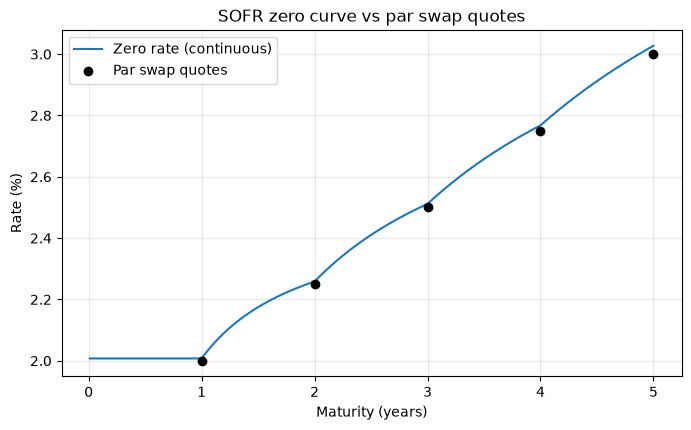

In [18]:
t_fine = np.linspace(0.01, 5, 500)

plt.figure(figsize=(8, 4.5))
plt.plot(t_fine, curve.zero(t_fine) * 100, label="Zero rate (continuous)")
plt.scatter(maturities, quotes * 100, color="black", zorder=3, label="Par swap quotes")
plt.xlabel("Maturity (years)")
plt.ylabel("Rate (%)")
plt.title("SOFR zero curve vs par swap quotes")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("images/forwards.png", dpi=150, bbox_inches="tight")
plt.show()

The zero rate is flat during the first year, because there is only one forward rate
between 0 and 1 year.

After that, the curve has a small kink at each whole year. This is where the forward
rate jumps to a new level. The zero rate is the average of all forwards since today,
so it moves towards each new forward step by step, which gives the rounded shape
between two years.

The swap rates (black dots) are a bit below the zero curve. A swap rate is also an
average of forwards, but it gives more weight to the first years, where forwards
are lower.

## 2. Quarterly forward rates

From the curve I compute one forward rate for each quarter, which is the rate
for that 3-month period that we can lock in today:

$$
F_i = \frac{1}{\tau} \left( \frac{\mathrm{DF}(t_{i-1})}{\mathrm{DF}(t_i)} - 1 \right)
$$

with $\tau = 91.25/360$ (Act/360 convention).

The forwards are constant inside each year because of the log-linear interpolation,
so the graph looks like stairs. The red dashed line is the strike of the cap (3%).

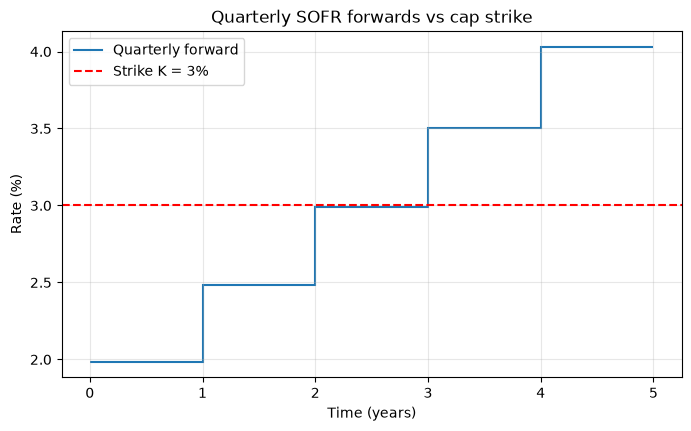

In [5]:
K = 0.03

plt.figure(figsize=(8, 4.5))
plt.stairs(F * 100, grid, label="Quarterly forward", linewidth=1.5, baseline=None)
plt.axhline(K * 100, color="red", linestyle="--", label="Strike K = 3%")
plt.xlabel("Time (years)")
plt.ylabel("Rate (%)")
plt.title("Quarterly SOFR forwards vs cap strike")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In years 1 and 2 the forwards are below 3%, so these caplets are out of the money.
In year 3 the forward is 2.99%, almost exactly at the strike.
In years 4 and 5 the forwards are above 3%, so these caplets are in the money.

So I expect most of the cap value to come from the last two years.

## 3. Pricing

Each caplet covers one quarter $[t_{i-1}, t_i]$ and pays at the end of the quarter, at $t_i$.
I price it with the Black-76 formula:

$$
\text{Caplet}_i = N \, \tau \, \mathrm{DF}(t_i) \left[ F_i \, \Phi(d_1) - K \, \Phi(d_2) \right]
$$

$$
d_{1,2} = \frac{\ln(F_i / K) \pm \frac{1}{2} \sigma^2 v_i}{\sigma \sqrt{v_i}}
$$

$F_i$ is the forward of the quarter, $K = 3\%$ is the strike and $\sigma = 20\%$ is the volatility.

One difference with the old LIBOR caplets is the time $v_i$. A LIBOR rate was fixed at the
start of the period, but compounded SOFR is only known at the end, so the rate is still
uncertain during the quarter. To take this into account I use the effective time from
Lyashenko and Mercurio:

$$
v_i = t_{i-1} + \frac{t_i - t_{i-1}}{3}
$$

The price of the cap is the sum of the 20 caplets.

In [6]:
N = 10e6
sigma = 0.2

cap_total, cap_contrib = cap_price(N, K, curve, sigma, kind="cap")
floor_total, floor_contrib = cap_price(N, K, curve, sigma, kind="floor")
swap = swap_pv(N, K, curve)

pricing = pd.Series({
    "Cap": cap_total,
    "Floor": floor_total,
    "Payer swap (quarterly, K)": swap,
    "Parity check: Cap - Floor - Swap": cap_total - floor_total - swap,
})
pricing.round(2).to_frame("USD")

,USD
Cap,223252.18
Floor,239168.41
"Payer swap (quarterly, K)",-15916.23
Parity check: Cap - Floor - Swap,-0.00


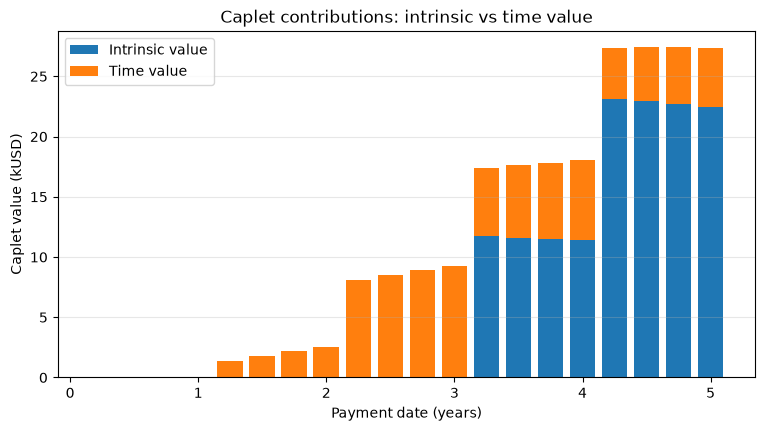

In [7]:
dfs_pay = curve.df(grid[1:])
intrinsic = N * TAU_QUARTER * dfs_pay * np.maximum(F - K, 0)
time_value = cap_contrib - intrinsic

plt.figure(figsize=(9, 4.5))
plt.bar(grid[1:], intrinsic / 1000, width=0.2, label="Intrinsic value")
plt.bar(grid[1:], time_value / 1000, width=0.2, bottom=intrinsic / 1000, label="Time value")
plt.xlabel("Payment date (years)")
plt.ylabel("Caplet value (kUSD)")
plt.title("Caplet contributions: intrinsic vs time value")
plt.grid(alpha=0.3, axis="y")
plt.legend()
plt.show()

The first caplets are out of the money, so their value is only time value: the chance
that rates go above 3% before they expire. The last caplets are in the money, and most
of their value is intrinsic value, what they would pay if rates stayed at the forward.

Inside year 5 the four caplets are worth almost the same (about 27k USD each).
The forward is the same for the whole year. Later caplets have a bit more time value,
but they are also discounted more, and the two effects roughly cancel.

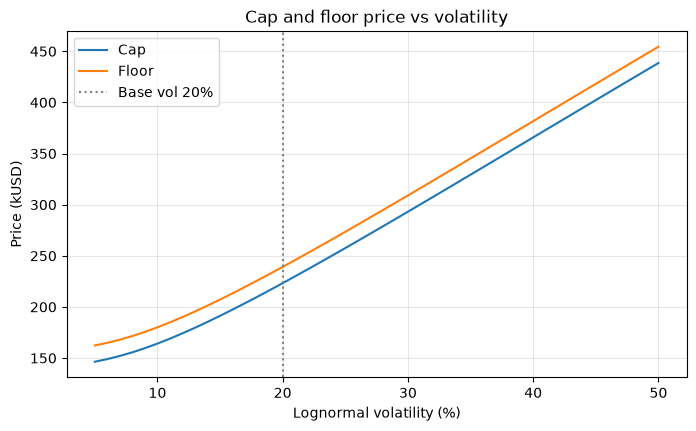

In [8]:
sigmas = np.linspace(0.05, 0.5, 46)
caps = np.array([cap_price(N, K, curve, s)[0] for s in sigmas])
floors = np.array([cap_price(N, K, curve, s, kind="floor")[0] for s in sigmas])

plt.figure(figsize=(8, 4.5))
plt.plot(sigmas * 100, caps / 1000, label="Cap")
plt.plot(sigmas * 100, floors / 1000, label="Floor")
plt.axvline(sigma * 100, color="grey", linestyle=":", label="Base vol 20%")
plt.xlabel("Lognormal volatility (%)")
plt.ylabel("Price (kUSD)")
plt.title("Cap and floor price vs volatility")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Both the cap and the floor get more expensive when volatility goes up. This makes
sense: more uncertainty on rates means a bigger chance that the options pay.

The two curves stay parallel. The gap is always about 15.9k USD, which is the value
of a payer swap at 3%. This comes from cap-floor parity: buying a cap and selling a
floor pays R − K every quarter, exactly like a swap, so the difference cannot depend
on the volatility.

## 4. Sensitivities

To measure the risk, I move one input a little, rebuild the whole curve, and reprice
the cap. I do it once up and once down, and take half of the difference:

$$
\Delta = \frac{P(s + h) - P(s - h)}{2}, \qquad h = 1\,\text{bp}
$$

Moving in both directions is more precise than moving only up, because the effect
of the curvature of the price cancels out.

I compute three sensitivities:
- **DV01**: all five swap rates move up by 1 bp together.
- **Bucket deltas**: only one swap rate moves at a time, which shows where the risk is.
- **Vega**: the volatility moves by 1 point (from 20% to 21%).

In [9]:
dv01_value = dv01(quotes, sigma)
deltas = bucket_deltas(quotes, sigma)
vega_value = vega(quotes, sigma)

risk = pd.Series({
    "DV01 (USD/bp)": dv01_value,
    "Sum of bucket deltas (USD/bp)": deltas.sum(),
    "Vega (USD/vol point)": vega_value,
})
risk.round(0).to_frame("Value")

,Value
DV01 (USD/bp),2066.0
Sum of bucket deltas (USD/bp),2065.0
Vega (USD/vol point),6678.0


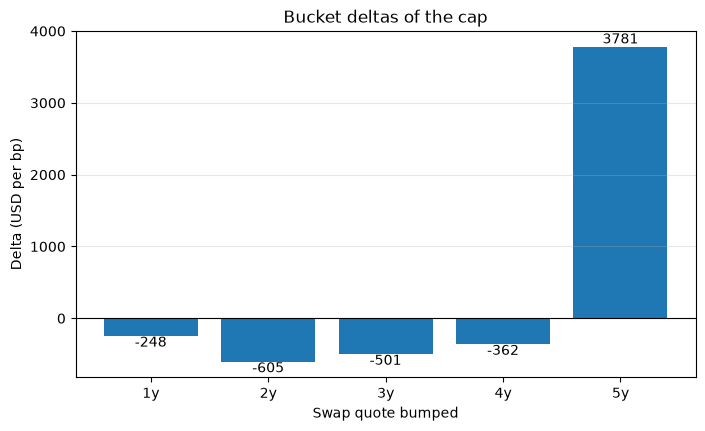

In [10]:
labels = ["1y", "2y", "3y", "4y", "5y"]

plt.figure(figsize=(8, 4.5))
bars = plt.bar(labels, deltas)
plt.bar_label(bars, fmt="%.0f")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Swap quote bumped")
plt.ylabel("Delta (USD per bp)")
plt.title("Bucket deltas of the cap")
plt.grid(alpha=0.3, axis="y")
plt.show()

Almost all the risk is on the 5y swap rate (+3,781 USD per bp out of a total of 2,066).

The 1y to 4y deltas are small and negative. When I raise one swap rate and keep the
others fixed, the bootstrap makes the forward of that year go up and the forward of the
next year go down by about the same amount. The caplets of the next year are worth more
and react more, so the cap loses a little. The 5y rate is the exception: there is no
year after it, so its forward just goes up.

The five bucket deltas add up to the DV01 (2,065 vs 2,066), which is a good check.

To hedge the delta, a desk that sold this cap could pay fixed on a 5y swap. The vega
cannot be hedged with swaps, because swaps are not options: it needs caps, floors or
swaptions.

## 5. Convexity

The DV01 says how much the cap gains for a 1 bp move. For a bigger move, the simple
estimate would be DV01 × number of bp, as if the price moved in a straight line.

Here I compare this estimate with the real P&L, where I reprice the cap after each shift.
The difference between the two shows the convexity (gamma) of the cap.

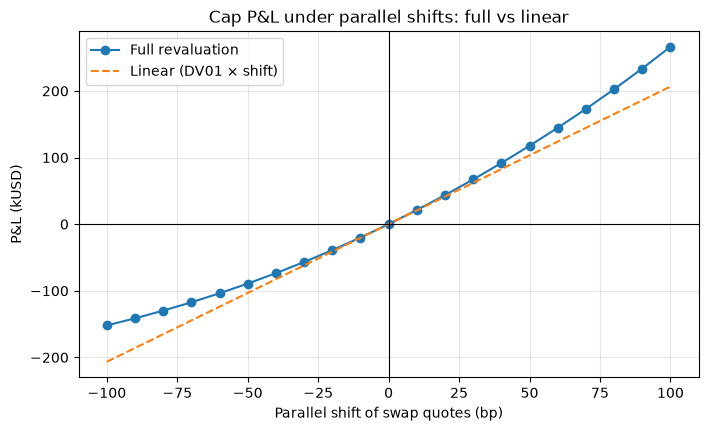

In [11]:
shifts_bp = np.arange(-100, 101, 10)
full_pnl = np.array([price_from_quotes(quotes + s * 1e-4, sigma) - cap_total for s in shifts_bp])
linear_pnl = dv01_value * shifts_bp

plt.figure(figsize=(8, 4.5))
plt.plot(shifts_bp, full_pnl / 1000, marker="o", label="Full revaluation")
plt.plot(shifts_bp, linear_pnl / 1000, linestyle="--", label="Linear (DV01 × shift)")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Parallel shift of swap quotes (bp)")
plt.ylabel("P&L (kUSD)")
plt.title("Cap P&L under parallel shifts: full vs linear")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [12]:
selected = [1, 10, 25, 50, 100]
convexity_table = pd.DataFrame({
    "Shift (bp)": selected,
    "Linear P&L": [dv01_value * s for s in selected],
    "Full P&L": [price_from_quotes(quotes + s * 1e-4, sigma) - cap_total for s in selected],
})
convexity_table["Convexity gap"] = convexity_table["Full P&L"] - convexity_table["Linear P&L"]
convexity_table.set_index("Shift (bp)").round(0)

,Linear P&L,Full P&L,Convexity gap
Shift (bp),,,
1,2066.0,2071.0,6.0
10,20656.0,21225.0,570.0
25,51639.0,55204.0,3565.0
50,103278.0,117607.0,14329.0
100,206555.0,266320.0,59764.0


In [13]:
steep_up = steepener(quotes, sigma, 1e-4)
steep_down = steepener(quotes, sigma, -1e-4)
steep_linear = np.sum(deltas * np.array([-1, -1, 1, 1, 1]))

pd.Series({
    "Steepener P&L (full)": steep_up,
    "Flattener P&L (full)": steep_down,
    "Linear estimate from bucket deltas": steep_linear,
    "Convexity: up + down": steep_up + steep_down,
}).round(0).to_frame("USD")

,USD
Steepener P&L (full),3827.0
Flattener P&L (full),-3715.0
Linear estimate from bucket deltas,3771.0
Convexity: up + down,112.0


On both sides, the real P&L is above the straight-line estimate: the cap gains more than
expected when rates go up and loses less than expected when they go down. This is what
being long convexity means.

The gap grows with the square of the shift. If I divide it by shift², I get about 5.7 USD
for every shift size, which means a gamma of about 11.5 USD per bp².

I also found that a 1 bp steepener gives a gap of 56 USD, ten times more than a 1 bp
parallel shift (about 5 USD). In a parallel shift every forward moves by about 1 bp.
In a steepener the 2y rate goes down while the 3y rate goes up, and the bootstrap turns
this into a move of several bp on the forwards in between.

## 6. Summary and limitations

| | Value |
|---|---|
| Cap price | 223,252 USD |
| Floor price | 239,168 USD |
| DV01 | +2,066 USD per bp |
| Vega | +6,678 USD per vol point |
| Gamma (parallel shifts) | about 11.5 USD per bp² |

I checked these results with unit tests. The strongest ones do not depend on the
volatility: cap minus floor must equal the swap, and at the at-the-money strike the cap
and the floor must have the same price. I also checked that with zero volatility the cap
is worth its intrinsic value, and that the bucket deltas add up to the DV01.